In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import f1_score

from src.architecture import build_transfer_model
from src.config import MODELS_DIR, SPLIT_MANIFEST_PATH
from src.preprocessing import dataset_from_manifest
from src.train import compute_balanced_class_weight

I0000 00:00:1792008765.223145    8864 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792008765.223621    8864 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792008765.275817    8864 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792008767.283902    8864 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
split = pd.read_csv(SPLIT_MANIFEST_PATH)

train_ds = dataset_from_manifest(split, "train", augment=True)
val_ds = dataset_from_manifest(split, "val")
y_val = split[split["split"] == "val"]["label"].values

pesos = compute_balanced_class_weight(split[split["split"] == "train"]["label"])
pesos = {clase: peso ** 0.5 for clase, peso in pesos.items()}

print("class_weight:", pesos)

class_weight: {0: 4.02077936060494, 1: 2.793671008037529, 2: 0.5965484229837177}


E0000 00:00:1792008768.370415    8864 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [3]:
class MejorF1(tf.keras.callbacks.Callback):
    def __init__(self, val_ds, y_val, ruta):
        super().__init__()
        self.val_ds = val_ds
        self.y_val = y_val
        self.ruta = ruta
        self.mejor = -1.0

    def on_epoch_end(self, epoch, logs=None):
        predicciones = self.model.predict(self.val_ds, verbose=0)
        y_pred = np.argmax(predicciones, axis=1)
        f1 = f1_score(self.y_val, y_pred, average="macro", zero_division=0)
        print(f" - val_f1_macro: {f1:.4f}")
        if f1 > self.mejor:
            self.mejor = f1
            self.model.save(self.ruta)
            print(" - modelo guardado")


def entrenar_variante(nombre, learning_rate, dropout, epochs=15):
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    ruta = MODELS_DIR / f"{nombre}.keras"

    modelo = build_transfer_model(learning_rate=learning_rate, dropout=dropout)
    callback = MejorF1(val_ds, y_val, ruta)

    historia = modelo.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=pesos,
        callbacks=[callback],
    )

    return {
        "nombre": nombre,
        "learning_rate": learning_rate,
        "dropout": dropout,
        "epochs": epochs,
        "val_f1_macro": round(callback.mejor, 4),
        "ruta": ruta,
        "historia": historia.history,
    }

In [4]:
run_1 = entrenar_variante("mango_lr1e-3_do0.3", learning_rate=0.001, dropout=0.3)

Epoch 1/15


/home/kevin/miniconda3/envs/Mangote/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.8925 - loss: 0.5780 - val_f1_macro: 0.5456
 - modelo guardado
85/85 ━━━━━━━━━━━━━━━━━━━━ 19s 172ms/step - accuracy: 0.8925 - loss: 0.5780 - val_accuracy: 0.9444 - val_loss: 0.2978
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.9485 - loss: 0.3118 - val_f1_macro: 0.6361
 - modelo guardado
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 142ms/step - accuracy: 0.9485 - loss: 0.3118 - val_accuracy: 0.9722 - val_loss: 0.1956
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9514 - loss: 0.2443 - val_f1_macro: 0.6374
 - modelo guardado
85/85 ━━━━━━━━━━━━━━━━━━━━ 13s 144ms/step - accuracy: 0.9514 - loss: 0.2443 - val_accuracy: 0.9792 - val_loss: 0.1741
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.9485 - loss: 0.2249 - val_f1_macro: 0.6374
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 137ms/step - accuracy: 0.9485 - loss: 0.2249 - val_accuracy: 0.9792 - val_loss: 0.1633
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/ste

In [5]:
run_2 = entrenar_variante("mango_lr1e-4_do0.5", learning_rate=0.0001, dropout=0.5)

Epoch 1/15


/home/kevin/miniconda3/envs/Mangote/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.7835 - loss: 0.6853 - val_f1_macro: 0.3238
 - modelo guardado
85/85 ━━━━━━━━━━━━━━━━━━━━ 20s 188ms/step - accuracy: 0.7835 - loss: 0.6853 - val_accuracy: 0.9444 - val_loss: 0.2790
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.8675 - loss: 0.6072 - val_f1_macro: 0.3238
85/85 ━━━━━━━━━━━━━━━━━━━━ 15s 174ms/step - accuracy: 0.8675 - loss: 0.6072 - val_accuracy: 0.9444 - val_loss: 0.2536
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8837 - loss: 0.5483 - val_f1_macro: 0.3238
85/85 ━━━━━━━━━━━━━━━━━━━━ 19s 157ms/step - accuracy: 0.8837 - loss: 0.5483 - val_accuracy: 0.9444 - val_loss: 0.2398
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8895 - loss: 0.5590 - val_f1_macro: 0.4202
 - modelo guardado
85/85 ━━━━━━━━━━━━━━━━━━━━ 14s 165ms/step - accuracy: 0.8895 - loss: 0.5590 - val_accuracy: 0.9514 - val_loss: 0.2406
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0

In [6]:
resultados = pd.DataFrame(
    [
        {k: v for k, v in r.items() if k not in ("historia", "ruta")}
        for r in (run_1, run_2)
    ]
)

resultados

,nombre,learning_rate,dropout,epochs,val_f1_macro
0,mango_lr1e-3_do0.3,0.0010,0.3,15,0.6630
1,mango_lr1e-4_do0.5,0.0001,0.5,15,0.5964


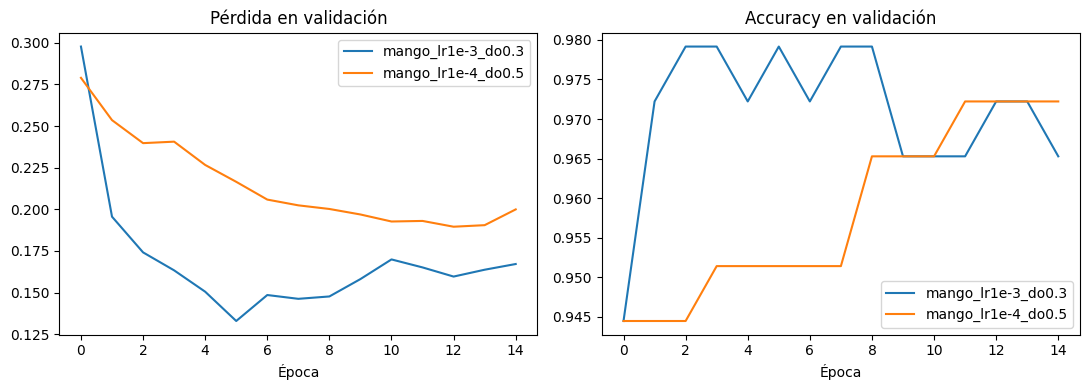

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

for r in (run_1, run_2):
    ejes[0].plot(r["historia"]["val_loss"], label=r["nombre"])
    ejes[1].plot(r["historia"]["val_accuracy"], label=r["nombre"])

ejes[0].set_title("Pérdida en validación")
ejes[1].set_title("Accuracy en validación")

for eje in ejes:
    eje.set_xlabel("Época")
    eje.legend()

plt.tight_layout()
plt.show()

In [8]:
mejor = max((run_1, run_2), key=lambda r: r["val_f1_macro"])

shutil.copy(mejor["ruta"], MODELS_DIR / "mango_final.keras")

print("Mejor variante:", mejor["nombre"])
print("F1 macro en validación:", mejor["val_f1_macro"])

Mejor variante: mango_lr1e-3_do0.3
F1 macro en validación: 0.663
